<a href="https://colab.research.google.com/github/shubhishukla8176-arch/exfoliation-energy-ml/blob/main/notebooks/06_exploratory_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive

drive.mount('/content/drive')

# Project folder
project_folder = "/content/drive/MyDrive/MASC520_Project"

# Load all three datasets
composition_df = pd.read_csv(
    os.path.join(
        project_folder,
        "model_ready_data",
        "composition_only.csv"
    )
)

structure_df = pd.read_csv(
    os.path.join(
        project_folder,
        "model_ready_data",
        "structure_only.csv"
    )
)

combined_df = pd.read_csv(
    os.path.join(
        project_folder,
        "model_ready_data",
        "combined_features.csv"
    )
)

datasets = {
    "Composition-only": composition_df,
    "Structure-only": structure_df,
    "Combined": combined_df
}

for name, df in datasets.items():
    print("\n", name)
    print("Shape:", df.shape)
    print("Materials:", df["jid"].nunique())


Mounted at /content/drive

 Composition-only
Shape: (813, 218)
Materials: 813

 Structure-only
Shape: (813, 24)
Materials: 813

 Combined
Shape: (813, 240)
Materials: 813


Exfoliation energy statistics:
count    813.000000
mean     110.972399
std      111.698983
min        0.030000
25%       58.760000
50%       81.290000
75%      108.180000
max      948.930000
Name: exfoliation_energy, dtype: float64


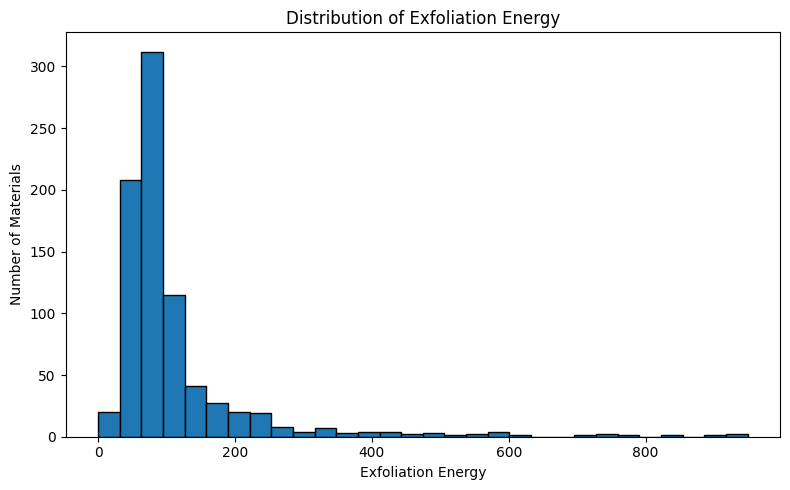

In [2]:

target = "exfoliation_energy"

print("Exfoliation energy statistics:")
print(combined_df[target].describe())

plt.figure(figsize=(8, 5))

plt.hist(
    combined_df[target],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Exfoliation Energy")
plt.ylabel("Number of Materials")
plt.title("Distribution of Exfoliation Energy")

plt.tight_layout()
plt.savefig(
    os.path.join(project_folder, "exfoliation_energy_distribution.png"),
    dpi=300
)
plt.show()


In [3]:

for name, df in datasets.items():

    print("\n" + "=" * 60)
    print(name)

    numerical_df = df.select_dtypes(include=[np.number])

    # Remove target from descriptor summary
    feature_df = numerical_df.drop(
        columns=["exfoliation_energy"],
        errors="ignore"
    )

    print("\nNumber of numerical descriptors:",
          feature_df.shape[1])

    print("\nFeature statistics:")
    display(feature_df.describe().T.head(15))



Composition-only

Number of numerical descriptors: 216

Feature statistics:


,count,mean,std,min,25%,50%,75%,max
fraction_Ag,813.0,0.010311,0.061157,0.0,0.0,0.0,0.0,0.666667
fraction_Al,813.0,0.008474,0.053981,0.0,0.0,0.0,0.0,0.666667
fraction_As,813.0,0.013230,0.081656,0.0,0.0,0.0,0.0,1.000000
fraction_Au,813.0,0.008160,0.053100,0.0,0.0,0.0,0.0,0.500000
fraction_B,813.0,0.004948,0.040726,0.0,0.0,0.0,0.0,0.500000
fraction_Ba,813.0,0.004755,0.043926,0.0,0.0,0.0,0.0,0.666667
fraction_Be,813.0,0.000615,0.017536,0.0,0.0,0.0,0.0,0.500000
fraction_Bi,813.0,0.021220,0.087226,0.0,0.0,0.0,0.0,1.000000
fraction_Br,813.0,0.063075,0.178810,0.0,0.0,0.0,0.0,0.800000
fraction_C,813.0,0.011161,0.066611,0.0,0.0,0.0,0.0,1.000000



Structure-only

Number of numerical descriptors: 20

Feature statistics:


,count,mean,std,min,25%,50%,75%,max
number_of_atoms,813.0,9.419434,6.792126,2.000000,5.000000,7.000000,12.000000,44.000000
lattice_a,813.0,5.367170,2.317137,2.282671,3.825910,4.347598,6.441876,21.314266
lattice_b,813.0,5.903583,2.522087,2.464998,3.925500,5.458450,7.088652,21.314268
lattice_c,813.0,8.927595,3.704681,2.828250,6.332890,8.003144,10.753168,32.237120
alpha,813.0,82.557978,22.549633,12.351500,90.000000,90.000000,90.000000,121.663100
beta,813.0,84.010648,23.515407,12.351400,90.000000,90.000000,90.000000,134.019300
gamma,813.0,88.925591,28.456230,12.351400,90.000000,90.000000,119.854800,139.048300
unit_cell_volume,813.0,223.850366,193.013961,29.114730,100.406838,159.138547,268.945576,1352.566490
volume_per_atom,813.0,23.414344,7.979023,7.542361,18.208939,22.919026,27.972594,78.851553
b_over_a,813.0,1.142634,0.387989,0.220418,1.000000,1.000000,1.085330,3.538108



Combined

Number of numerical descriptors: 236

Feature statistics:


,count,mean,std,min,25%,50%,75%,max
fraction_Ag,813.0,0.010311,0.061157,0.0,0.0,0.0,0.0,0.666667
fraction_Al,813.0,0.008474,0.053981,0.0,0.0,0.0,0.0,0.666667
fraction_As,813.0,0.013230,0.081656,0.0,0.0,0.0,0.0,1.000000
fraction_Au,813.0,0.008160,0.053100,0.0,0.0,0.0,0.0,0.500000
fraction_B,813.0,0.004948,0.040726,0.0,0.0,0.0,0.0,0.500000
fraction_Ba,813.0,0.004755,0.043926,0.0,0.0,0.0,0.0,0.666667
fraction_Be,813.0,0.000615,0.017536,0.0,0.0,0.0,0.0,0.500000
fraction_Bi,813.0,0.021220,0.087226,0.0,0.0,0.0,0.0,1.000000
fraction_Br,813.0,0.063075,0.178810,0.0,0.0,0.0,0.0,0.800000
fraction_C,813.0,0.011161,0.066611,0.0,0.0,0.0,0.0,1.000000


In [4]:

for name, df in datasets.items():

    print("\n", name)

    features = df.drop(
        columns=["jid", "exfoliation_energy"],
        errors="ignore"
    )

    constant_columns = [
        col for col in features.columns
        if features[col].nunique(dropna=False) <= 1
    ]

    print("Number of constant features:",
          len(constant_columns))

    print("Constant feature names:")
    print(constant_columns)



 Composition-only
Number of constant features: 5
Constant feature names:
['magpie_MagpieData maximum NsValence', 'magpie_MagpieData minimum NsUnfilled', 'magpie_MagpieData minimum NdUnfilled', 'magpie_MagpieData minimum NfUnfilled', 'magpie_MagpieData minimum GSmagmom']

 Structure-only
Number of constant features: 0
Constant feature names:
[]

 Combined
Number of constant features: 5
Constant feature names:
['magpie_MagpieData maximum NsValence', 'magpie_MagpieData minimum NsUnfilled', 'magpie_MagpieData minimum NdUnfilled', 'magpie_MagpieData minimum NfUnfilled', 'magpie_MagpieData minimum GSmagmom']


In [5]:

# Use the combined dataset for initial correlation analysis

numeric_df = combined_df.select_dtypes(
    include=[np.number]
)

correlation = numeric_df.corr()

# Correlation of each numerical feature with the target
target_correlation = (
    correlation["exfoliation_energy"]
    .drop("exfoliation_energy")
    .sort_values(key=abs, ascending=False)
)

print("Top 20 numerical features correlated with exfoliation energy:")

display(target_correlation.head(20).to_frame(
    name="Pearson correlation"
))


Top 20 numerical features correlated with exfoliation energy:


,Pearson correlation
coordination_min,0.354152
magpie_MagpieData maximum MendeleevNumber,-0.348882
magpie_MagpieData maximum NpValence,-0.347504
magpie_MagpieData maximum Column,-0.345674
coordination_mean,0.304715
weighted_coordination_mean,0.304715
magpie_MagpieData mode GSmagmom,0.279554
magpie_MagpieData mode SpaceGroupNumber,0.270313
magpie_MagpieData mean NpValence,-0.264516
magpie_MagpieData minimum SpaceGroupNumber,0.255974


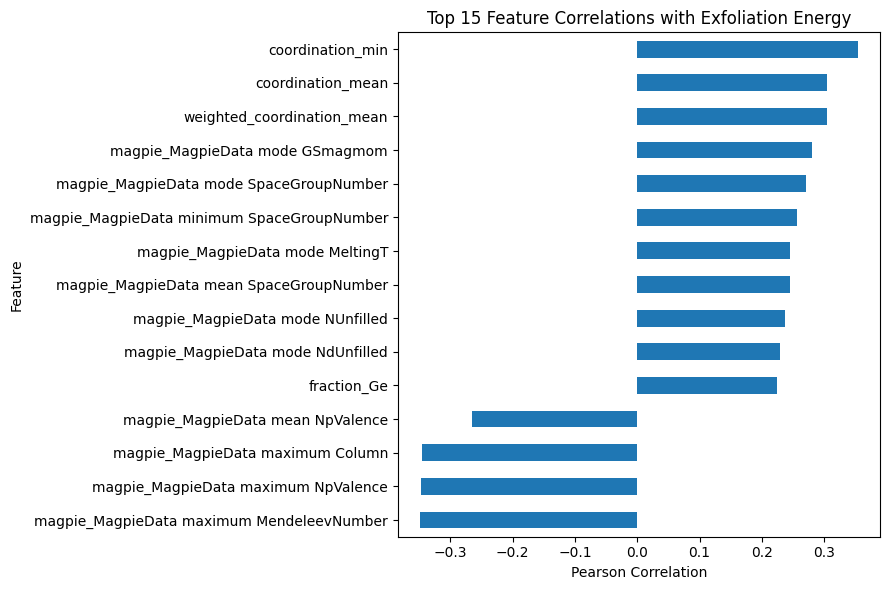

In [6]:

top_correlations = target_correlation.head(15)

plt.figure(figsize=(9, 6))

top_correlations.sort_values().plot(
    kind="barh"
)

plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.title("Top 15 Feature Correlations with Exfoliation Energy")

plt.tight_layout()
plt.savefig(
    os.path.join(project_folder, "target_feature_correlations.png"),
    dpi=300
)
plt.show()


In [7]:

categorical_columns = structure_df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

for col in categorical_columns:

    print("\nDistribution of", col)

    display(
        structure_df[col].value_counts().head(20).to_frame(
            name="Number of materials"
        )
    )


Categorical columns:
['jid', 'spacegroup_symbol', 'crystal_system']

Distribution of jid


,Number of materials
jid,
JVASP-10,1
JVASP-10173,1
JVASP-10177,1
JVASP-10209,1
JVASP-10571,1
JVASP-1067,1
JVASP-1070,1
JVASP-10734,1
JVASP-10796,1



Distribution of spacegroup_symbol


,Number of materials
spacegroup_symbol,
R-3m,96
P-3m1,95
P4/nmm,84
C2/m,50
P6_3/mmc,39
Pmmn,38
Pnma,38
Cmcm,37
P2_1/c,33



Distribution of crystal_system


,Number of materials
crystal_system,
trigonal,263
orthorhombic,195
monoclinic,148
tetragonal,123
hexagonal,63
triclinic,18
cubic,3


In [8]:

# Numerical descriptors only
feature_numeric = combined_df.select_dtypes(
    include=[np.number]
).drop(
    columns=["exfoliation_energy"],
    errors="ignore"
)

feature_corr = feature_numeric.corr().abs()

# Upper triangle avoids duplicate pairs
upper_triangle = feature_corr.where(
    np.triu(
        np.ones(feature_corr.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = (
    upper_triangle.stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Absolute correlation"
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Absolute correlation"] > 0.95
].sort_values(
    "Absolute correlation",
    ascending=False
)

print("Number of highly correlated feature pairs:",
      len(high_corr_pairs))

display(high_corr_pairs.head(30))


Number of highly correlated feature pairs: 54


,Feature 1,Feature 2,Absolute correlation
21105,magpie_MagpieData minimum NsValence,magpie_MagpieData range NsValence,1.000000
23715,magpie_MagpieData maximum NsUnfilled,magpie_MagpieData range NsUnfilled,1.000000
25899,magpie_MagpieData maximum GSmagmom,magpie_MagpieData range GSmagmom,1.000000
26540,coordination_mean,weighted_coordination_mean,1.000000
24795,magpie_MagpieData maximum NfUnfilled,magpie_MagpieData range NfUnfilled,1.000000
24485,magpie_MagpieData maximum NdUnfilled,magpie_MagpieData range NdUnfilled,1.000000
26334,stoich_7-norm,stoich_10-norm,0.999406
15100,magpie_MagpieData maximum Number,magpie_MagpieData maximum AtomicWeight,0.999198
26312,stoich_5-norm,stoich_7-norm,0.998920
15401,magpie_MagpieData mean Number,magpie_MagpieData mean AtomicWeight,0.998911


In [9]:

eda_folder = os.path.join(
    project_folder,
    "eda_results"
)

os.makedirs(eda_folder, exist_ok=True)

# Save target statistics
combined_df["exfoliation_energy"].describe().to_csv(
    os.path.join(eda_folder, "target_statistics.csv")
)

# Save target correlations
target_correlation.to_csv(
    os.path.join(eda_folder, "target_correlations.csv")
)

# Save highly correlated feature pairs
high_corr_pairs.to_csv(
    os.path.join(eda_folder, "highly_correlated_features.csv"),
    index=False
)

print("EDA results saved successfully!")
print("Location:", eda_folder)


EDA results saved successfully!
Location: /content/drive/MyDrive/MASC520_Project/eda_results
